# Fair, Interpretable, and Actionable Readmission Risk Modeling

**Digital Health & Medical Data Science Track**  
**Part 1: Data Cleaning and Exploratory Data Analysis**


## Data Cleaning and Quality Checks


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", None)
RANDOM_STATE = 123

In [2]:
DATA_DIR = Path(r"..\Data")

df_raw = pd.read_csv(
    DATA_DIR / "diabetic_data.csv",
    keep_default_na=False
)

id_mapping = pd.read_csv(
    DATA_DIR / "IDS_mapping.csv",
    keep_default_na=False
)

print("Dataset shape:", df_raw.shape)
df_raw.head()

Dataset shape: (101766, 50)


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,?,Pediatrics-Endocrinology,41,0,1,0,0,0,250.83,?,?,1,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,?,?,59,0,18,0,0,0,276,250.01,255,9,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,?,?,11,5,13,2,0,1,648,250,V27,6,None,None,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,?,?,44,1,16,0,0,0,8,250.43,403,7,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,?,?,51,0,8,0,0,0,197,157,250,5,None,None,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [3]:
df = df_raw.copy()

print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")

Rows: 101,766
Columns: 50


In [4]:
display(df.head())

print("\nData types:")
display(df.dtypes.to_frame("dtype"))

print("\nUnique values per column:")
display(
    df.nunique(dropna=False)
      .sort_values()
      .to_frame("n_unique")
)

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,?,Pediatrics-Endocrinology,41,0,1,0,0,0,250.83,?,?,1,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,?,?,59,0,18,0,0,0,276,250.01,255,9,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,?,?,11,5,13,2,0,1,648,250,V27,6,None,None,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,?,?,44,1,16,0,0,0,8,250.43,403,7,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,?,?,51,0,8,0,0,0,197,157,250,5,None,None,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,NO



Data types:


,dtype
encounter_id,int64
patient_nbr,int64
race,object
gender,object
age,object
weight,object
admission_type_id,int64
discharge_disposition_id,int64
admission_source_id,int64
time_in_hospital,int64



Unique values per column:


,n_unique
examide,1
citoglipton,1
troglitazone,2
acetohexamide,2
tolbutamide,2
glipizide-metformin,2
diabetesMed,2
metformin-rosiglitazone,2
change,2
glimepiride-pioglitazone,2


### Dataset structure

The dataset contains **101,766 hospital encounters** and **50 original variables**. Each row represents an encounter rather than a unique patient, so patient-level repetition must be handled separately from duplicate rows.


### Identifier and Repeat Encounter Audit


In [5]:
id_audit = pd.Series({
    "rows": len(df),
    "unique_encounter_id": df["encounter_id"].nunique(),
    "duplicate_encounter_id": df["encounter_id"].duplicated().sum(),
    "unique_patients": df["patient_nbr"].nunique(),
    "exact_duplicate_rows": df.duplicated().sum()
})

display(id_audit)

rows                      101766
unique_encounter_id       101766
duplicate_encounter_id         0
unique_patients            71518
exact_duplicate_rows           0
dtype: int64

In [6]:
encounters_per_patient = (
    df.groupby("patient_nbr")
      .size()
      .rename("n_encounters")
)

repeat_summary = pd.Series({
    "unique_patients": len(encounters_per_patient),

    "patients_with_one_encounter":
        (encounters_per_patient == 1).sum(),

    "patients_with_multiple_encounters":
        (encounters_per_patient > 1).sum(),

    "max_encounters_for_one_patient":
        encounters_per_patient.max()
})

display(repeat_summary)

unique_patients                      71518
patients_with_one_encounter          54745
patients_with_multiple_encounters    16773
max_encounters_for_one_patient          40
dtype: int64

In [7]:
df["repeat_patient"] = df["patient_nbr"].isin(
    encounters_per_patient[encounters_per_patient > 1].index
)

### Finding

There are **101,766 unique encounter IDs** and no exact duplicate rows. The data contain **71,518 unique patients**, and **16,773 patients** have more than one encounter. Repeated `patient_nbr` values therefore represent repeat hospital encounters, not duplicate records. They are retained for analysis, while `patient_nbr` should later be used to keep the same patient within one data split and prevent leakage.


### Missing Data


In [8]:
def count_missing_values(series):
    actual_na = series.isna().sum()

    question_mark_missing = (
        series.astype("string")
        .str.strip()
        .eq("?")
        .sum()
    )

    return actual_na + question_mark_missing


missing_summary = pd.DataFrame({
    "missing_count": df.apply(count_missing_values)
})

missing_summary["missing_percent"] = (
    missing_summary["missing_count"] / len(df) * 100
)

missing_summary = missing_summary.sort_values(
    "missing_percent",
    ascending=False
)

display(missing_summary)

,missing_count,missing_percent
weight,98569,96.858479
medical_specialty,49949,49.082208
payer_code,40256,39.557416
race,2273,2.233555
diag_3,1423,1.398306
diag_2,358,0.351787
diag_1,21,0.020636
encounter_id,0,0.000000
tolazamide,0,0.000000
glyburide,0,0.000000


In [9]:
missing_report = (
    missing_summary
    .query("missing_count > 0")
    .copy()
)

missing_report["decision"] = ""
missing_report["reason"] = ""

display(missing_report)

,missing_count,missing_percent,decision,reason
weight,98569,96.858479,,
medical_specialty,49949,49.082208,,
payer_code,40256,39.557416,,
race,2273,2.233555,,
diag_3,1423,1.398306,,
diag_2,358,0.351787,,
diag_1,21,0.020636,,


In [10]:
constant_columns = [
    col for col in df.columns
    if df[col].nunique(dropna=False) == 1
]

print("Constant columns:")
print(constant_columns)

Constant columns:
['examide', 'citoglipton']


In [11]:
categorical_cols = df.select_dtypes(
    include=["object", "string"]
).columns
rare_category_summary = []

for col in categorical_cols:
    counts = df[col].value_counts(dropna=False)
    proportions = df[col].value_counts(
        normalize=True,
        dropna=False
    )

    rare_levels = proportions[proportions < 0.01]

    rare_category_summary.append({
        "variable": col,
        "n_levels": df[col].nunique(dropna=False),
        "rare_levels_below_1pct": len(rare_levels)
    })

rare_category_summary = pd.DataFrame(rare_category_summary)

display(
    rare_category_summary.sort_values(
        "rare_levels_below_1pct",
        ascending=False
    )
)

,variable,n_levels,rare_levels_below_1pct
8,diag_3,790,770
7,diag_2,749,725
6,diag_1,717,694
5,medical_specialty,73,63
3,weight,10,8
4,payer_code,18,8
23,miglitol,4,3
22,acarbose,4,3
29,glyburide-metformin,4,3
13,nateglinide,4,3


In [12]:
for col in ["A1Cresult", "max_glu_serum"]:
    print(f"\n{col}")
    print(df[col].value_counts(dropna=False))


A1Cresult
A1Cresult
None    84748
>8       8216
Norm     4990
>7       3812
Name: count, dtype: int64

max_glu_serum
max_glu_serum
None    96420
Norm     2597
>200     1485
>300     1264
Name: count, dtype: int64


### Finding

Missingness is concentrated in a small number of variables. `weight` is missing in about **96.9%** of encounters, `medical_specialty` in about **49.1%**, and `payer_code` in about **39.6%**. Missingness is much lower for `race` and the diagnosis fields. Values such as `None` in `A1Cresult` and `max_glu_serum` are kept as recorded categories rather than automatically treated as missing.


In [13]:
df_clean = df.copy()

In [14]:
missing_as_category_cols = [
    "medical_specialty",
    "payer_code",
    "race",
    "diag_1",
    "diag_2",
    "diag_3"
]

for col in missing_as_category_cols:
    df_clean[col] = df_clean[col].replace("?", "Missing")

In [15]:
missing_decisions = pd.DataFrame({
    "variable": [
        "weight",
        "medical_specialty",
        "payer_code",
        "race",
        "diag_1",
        "diag_2",
        "diag_3"
    ],
    "missing_percent": [
        96.858479,
        49.082208,
        39.557416,
        2.233555,
        0.020636,
        0.351787,
        1.398306
    ],
    "decision": [
        "Exclude from modeling",
        "Retain; encode missing as category",
        "Retain for now; encode missing as category",
        "Retain; encode missing as category",
        "Retain; encode missing as category",
        "Retain; encode missing as category",
        "Retain; encode missing as category"
    ],
    "reason": [
        "Extremely high missingness",
        "Potentially informative categorical variable",
        "Potentially informative; modeling value to be assessed later",
        "Required for subgroup and fairness analysis",
        "Very low missingness",
        "Low missingness",
        "Low missingness"
    ]
})

display(missing_decisions)

,variable,missing_percent,decision,reason
0,weight,96.858479,Exclude from modeling,Extremely high missingness
1,medical_specialty,49.082208,Retain; encode missing as category,Potentially informative categorical variable
2,payer_code,39.557416,Retain for now; encode missing as category,Potentially informative; modeling value to be ...
3,race,2.233555,Retain; encode missing as category,Required for subgroup and fairness analysis
4,diag_1,0.020636,Retain; encode missing as category,Very low missingness
5,diag_2,0.351787,Retain; encode missing as category,Low missingness
6,diag_3,1.398306,Retain; encode missing as category,Low missingness


In [16]:
special_tokens = [
    "?",
    "Unknown/Invalid",
    "Unknown",
    "Not Available",
    "Not Mapped",
    "NULL"
]

special_value_summary = []

for col in categorical_cols:
    value_counts = df[col].value_counts(dropna=False)

    for token in special_tokens:
        if token in value_counts.index:
            special_value_summary.append({
                "variable": col,
                "value": token,
                "count": value_counts[token],
                "percent": value_counts[token] / len(df) * 100
            })

special_value_summary = pd.DataFrame(special_value_summary)

display(
    special_value_summary.sort_values(
        "percent",
        ascending=False
    )
)

,variable,value,count,percent
2,weight,?,98569,96.858479
4,medical_specialty,?,49949,49.082208
3,payer_code,?,40256,39.557416
0,race,?,2273,2.233555
7,diag_3,?,1423,1.398306
6,diag_2,?,358,0.351787
5,diag_1,?,21,0.020636
1,gender,Unknown/Invalid,3,0.002948


### Missing-data decisions

`weight` is marked for exclusion from modeling because almost the entire column is missing. Other incomplete categorical variables are retained, with missing values represented explicitly so that observations are not discarded unnecessarily. `race` is retained because it is also needed for later subgroup and fairness analysis.


### Administrative Codes and Special Categories


In [17]:
display(id_mapping.head(15))

,admission_type_id,description
0,1,Emergency
1,2,Urgent
2,3,Elective
3,4,Newborn
4,5,Not Available
5,6,NULL
6,7,Trauma Center
7,8,Not Mapped
8,,
9,discharge_disposition_id,description


In [18]:
admission_type_map = {
    1: "Emergency",
    2: "Urgent",
    3: "Elective",
    4: "Newborn",
    5: "Not Available",
    6: "NULL",
    7: "Trauma Center",
    8: "Not Mapped"
}

df_clean["admission_type"] = (
    df_clean["admission_type_id"]
    .map(admission_type_map)
)

In [19]:
discharge_counts = (
    df["discharge_disposition_id"]
    .value_counts()
    .sort_index()
    .to_frame("count")
)

discharge_counts["percent"] = (
    discharge_counts["count"] / len(df) * 100
)

display(discharge_counts)

,count,percent
discharge_disposition_id,,
1,60234,59.188727
2,2128,2.091072
3,13954,13.711849
4,815,0.800857
5,1184,1.163453
6,12902,12.678105
7,623,0.612189
8,108,0.106126
9,21,0.020636


In [20]:
death_hospice_ids = [11, 13, 14, 19, 20, 21]

df_clean["death_or_hospice"] = (
    df_clean["discharge_disposition_id"]
    .isin(death_hospice_ids)
)

death_hospice_summary = (
    df_clean["death_or_hospice"]
    .value_counts()
    .to_frame("count")
)

death_hospice_summary["percent"] = (
    death_hospice_summary["count"]
    / len(df_clean)
    * 100
)

display(death_hospice_summary)

,count,percent
death_or_hospice,,
False,99343,97.619048
True,2423,2.380952


### Finding

Admission, discharge, and admission-source IDs are categorical codes rather than quantitative measurements. They are mapped to readable labels for interpretation. **2,423 encounters (about 2.38%)** are flagged as death or hospice discharges. These encounters remain in the EDA, but the modeling stage should explicitly decide whether they belong in the prediction cohort because they may not have the same opportunity for later readmission.


In [21]:
constant_decisions = pd.DataFrame({
    "variable": ["examide", "citoglipton"],
    "decision": [
        "Exclude from modeling",
        "Exclude from modeling"
    ],
    "reason": [
        "Constant feature with no variance",
        "Constant feature with no variance"
    ]
})

display(constant_decisions)

,variable,decision,reason
0,examide,Exclude from modeling,Constant feature with no variance
1,citoglipton,Exclude from modeling,Constant feature with no variance


`examide` and `citoglipton` have no variation in this dataset, so they do not provide predictive information and are marked for exclusion from modeling.


### Outlier and Plausibility Screening


In [22]:
numeric_clinical_cols = [
    "time_in_hospital",
    "num_lab_procedures",
    "num_procedures",
    "num_medications",
    "number_outpatient",
    "number_emergency",
    "number_inpatient",
    "number_diagnoses"
]

In [23]:
outlier_summary = []

for col in numeric_clinical_cols:
    s = df_clean[col]

    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1

    lower_fence = q1 - 1.5 * iqr
    upper_fence = q3 + 1.5 * iqr

    outlier_mask = (
        (s < lower_fence) |
        (s > upper_fence)
    )

    outlier_summary.append({
        "variable": col,
        "min": s.min(),
        "q1": q1,
        "median": s.median(),
        "mean": s.mean(),
        "q3": q3,
        "max": s.max(),
        "IQR": iqr,
        "lower_fence": lower_fence,
        "upper_fence": upper_fence,
        "n_IQR_flagged": outlier_mask.sum(),
        "percent_IQR_flagged": outlier_mask.mean() * 100,
        "percent_zero": (s == 0).mean() * 100
    })

outlier_summary = pd.DataFrame(outlier_summary)

display(
    outlier_summary.round(2)
)

,variable,min,q1,median,mean,q3,max,IQR,lower_fence,upper_fence,n_IQR_flagged,percent_IQR_flagged,percent_zero
0,time_in_hospital,1,2.0,4.0,4.40,6.0,14,4.0,-4.0,12.0,2252,2.21,0.00
1,num_lab_procedures,1,31.0,44.0,43.10,57.0,132,26.0,-8.0,96.0,143,0.14,0.00
2,num_procedures,0,0.0,1.0,1.34,2.0,6,2.0,-3.0,5.0,4954,4.87,45.84
3,num_medications,1,10.0,15.0,16.02,20.0,81,10.0,-5.0,35.0,2557,2.51,0.00
4,number_outpatient,0,0.0,0.0,0.37,0.0,42,0.0,0.0,0.0,16739,16.45,83.55
5,number_emergency,0,0.0,0.0,0.20,0.0,76,0.0,0.0,0.0,11383,11.19,88.81
6,number_inpatient,0,0.0,0.0,0.64,1.0,21,1.0,-1.5,2.5,7049,6.93,66.46
7,number_diagnoses,1,6.0,8.0,7.42,9.0,16,3.0,1.5,13.5,281,0.28,0.00


### Finding

The 1.5 × IQR rule flags several observations, especially in prior outpatient and emergency visit counts. These variables are strongly zero-inflated, so a standard IQR rule can label many valid nonzero values as outliers. For that reason, IQR is used as a **screening tool**, not as an automatic deletion rule.


In [24]:
range_summary = pd.DataFrame({
    "variable": numeric_clinical_cols,
    "min": [df_clean[col].min() for col in numeric_clinical_cols],
    "max": [df_clean[col].max() for col in numeric_clinical_cols],
    "n_unique": [
        df_clean[col].nunique()
        for col in numeric_clinical_cols
    ]
})

display(range_summary)

,variable,min,max,n_unique
0,time_in_hospital,1,14,14
1,num_lab_procedures,1,132,118
2,num_procedures,0,6,7
3,num_medications,1,81,75
4,number_outpatient,0,42,39
5,number_emergency,0,76,33
6,number_inpatient,0,21,21
7,number_diagnoses,1,16,16


In [25]:
for col in numeric_clinical_cols:
    print(f"\nTop values for {col}")

    display(
        df_clean[col]
        .value_counts()
        .sort_index(ascending=False)
        .head(10)
        .to_frame("count")
    )


Top values for time_in_hospital


,count
time_in_hospital,
14,1042
13,1210
12,1448
11,1855
10,2342
9,3002
8,4391
7,5859
6,7539



Top values for num_lab_procedures


,count
num_lab_procedures,
132,1
129,1
126,1
121,1
120,1
118,1
114,2
113,3
111,3



Top values for num_procedures


...

,count
number_emergency,
76,1
64,1
63,1
54,1
46,1
42,1
37,1
29,1
28,1



Top values for number_inpatient


,count
number_inpatient,
21,1
19,2
18,1
17,1
16,6
15,9
14,10
13,20
12,34



Top values for number_diagnoses


,count
number_diagnoses,
16,45
15,10
14,7
13,16
12,9
11,11
10,17
9,49474
8,10616


### Decision

Observed ranges were reviewed separately from statistical outlier flags. No numeric observations were removed solely because they fell outside the IQR limits. Extreme healthcare-utilization values may represent genuine high-utilization patients rather than data errors.


## Q1 — What does the readmission population look like?


In [26]:
target_counts = (
    df_clean["readmitted"]
    .value_counts()
    .reindex(["NO", ">30", "<30"])
)

target_summary = pd.DataFrame({
    "count": target_counts,
    "percent": target_counts / len(df_clean) * 100
})

display(target_summary.round(2))

,count,percent
readmitted,,
NO,54864,53.91
>30,35545,34.93
<30,11357,11.16


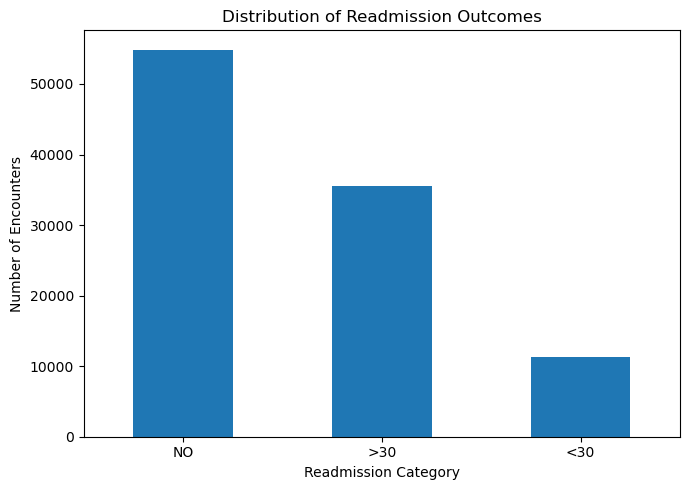

In [27]:
fig, ax = plt.subplots(figsize=(7, 5))

target_counts.plot(
    kind="bar",
    ax=ax
)

ax.set_title("Distribution of Readmission Outcomes")
ax.set_xlabel("Readmission Category")
ax.set_ylabel("Number of Encounters")

plt.xticks(rotation=0)
plt.tight_layout()
fig.savefig(r"../Figures/Distribution of Readmission Outcomes.png", dpi=300, bbox_inches="tight")
plt.show()

### Figure interpretation: Readmission outcome

The outcome is clearly imbalanced. Most encounters were not followed by a recorded readmission, while readmission within 30 days (`<30`) is the smallest class at about **11.2%** of encounters. This imbalance means that later model evaluation should not rely on overall Accuracy alone.


In [28]:
population_summary = pd.Series({
    "encounters": len(df_clean),
    "unique_patients": df_clean["patient_nbr"].nunique(),
    "patients_with_multiple_encounters":
        (encounters_per_patient > 1).sum(),
    "maximum_encounters_per_patient":
        encounters_per_patient.max(),
    "death_or_hospice_encounters":
        df_clean["death_or_hospice"].sum(),
    "early_readmissions_<30":
        (df_clean["readmitted"] == "<30").sum()
})

display(population_summary)

encounters                           101766
unique_patients                       71518
patients_with_multiple_encounters     16773
maximum_encounters_per_patient           40
death_or_hospice_encounters            2423
early_readmissions_<30                11357
dtype: int64

### Population summary

The analysis includes **101,766 encounters from 71,518 unique patients**. Early readmission within 30 days occurred in **11,357 encounters**. Repeat encounters are common enough that patient-level leakage is an important issue for the modeling stage.


In [29]:
age_order = [
    "[0-10)",
    "[10-20)",
    "[20-30)",
    "[30-40)",
    "[40-50)",
    "[50-60)",
    "[60-70)",
    "[70-80)",
    "[80-90)",
    "[90-100)"
]

age_counts = (
    df_clean["age"]
    .value_counts()
    .reindex(age_order)
)

display(age_counts.to_frame("count"))

,count
age,
[0-10),161
[10-20),691
[20-30),1657
[30-40),3775
[40-50),9685
[50-60),17256
[60-70),22483
[70-80),26068
[80-90),17197


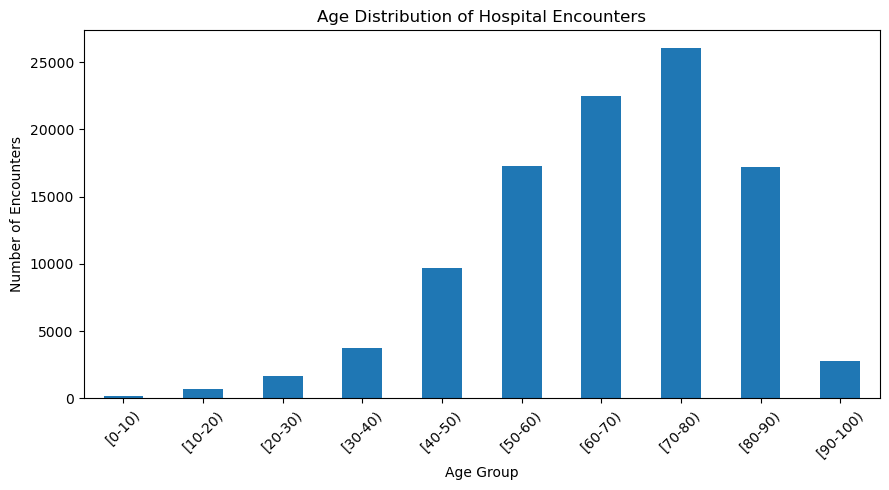

In [30]:
fig, ax = plt.subplots(figsize=(9, 5))

age_counts.plot(
    kind="bar",
    ax=ax
)

ax.set_title("Age Distribution of Hospital Encounters")
ax.set_xlabel("Age Group")
ax.set_ylabel("Number of Encounters")

plt.xticks(rotation=45)
plt.tight_layout()
fig.savefig("../Figures/Age Distribution of Hospital Encounters.png", dpi=300, bbox_inches="tight")
plt.show()

### Figure interpretation: Age distribution

Most encounters occur among older adults. The **70–80 year** group is the largest, followed by the 60–70 and 80–90 year groups. Younger age groups are much smaller, so percentages calculated for those groups should be interpreted together with their sample sizes.


In [31]:
for col in ["race", "gender"]:
    summary = pd.DataFrame({
        "count": df_clean[col].value_counts(dropna=False),
        "percent": df_clean[col].value_counts(
            normalize=True,
            dropna=False
        ) * 100
    })

    print(f"\n{col.upper()}")
    display(summary.round(2))


RACE


,count,percent
race,,
Caucasian,76099,74.78
AfricanAmerican,19210,18.88
Missing,2273,2.23
Hispanic,2037,2.00
Other,1506,1.48
Asian,641,0.63



GENDER


,count,percent
gender,,
Female,54708,53.76
Male,47055,46.24
Unknown/Invalid,3,0.00


### Demographic description

The sample is predominantly Caucasian, followed by African American patients. Female and male encounters are both well represented. Race contains a small amount of missing information, which is retained rather than dropping those encounters.


In [32]:
df_clean["gender"] = (
    df_clean["gender"]
    .replace("Unknown/Invalid", "Missing")
)

In [33]:
df_clean["early_readmission"] = (
    df_clean["readmitted"] == "<30"
).astype(int)

In [34]:
age_readmission = (
    df_clean
    .groupby("age", observed=False)["early_readmission"]
    .agg(["count", "sum", "mean"])
    .reindex(age_order)
)

age_readmission["early_readmission_percent"] = (
    age_readmission["mean"] * 100
)

display(
    age_readmission[
        ["count", "sum", "early_readmission_percent"]
    ].round(2)
)

,count,sum,early_readmission_percent
age,,,
[0-10),161,3,1.86
[10-20),691,40,5.79
[20-30),1657,236,14.24
[30-40),3775,424,11.23
[40-50),9685,1027,10.60
[50-60),17256,1668,9.67
[60-70),22483,2502,11.13
[70-80),26068,3069,11.77
[80-90),17197,2078,12.08


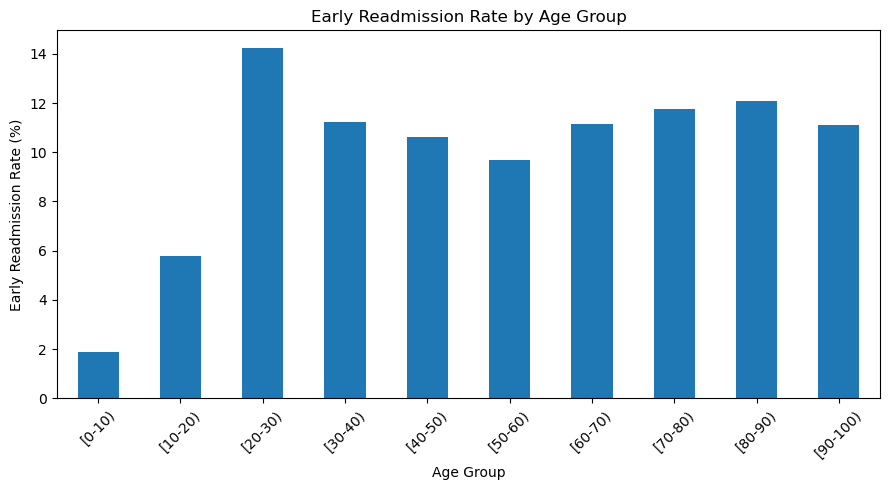

In [35]:
fig, ax = plt.subplots(figsize=(9, 5))

age_readmission["early_readmission_percent"].plot(
    kind="bar",
    ax=ax
)

ax.set_title("Early Readmission Rate by Age Group")
ax.set_xlabel("Age Group")
ax.set_ylabel("Early Readmission Rate (%)")

plt.xticks(rotation=45)
plt.tight_layout()
fig.savefig("../Figures/Early Readmission Rate by Age Group.png", dpi=300, bbox_inches="tight")
plt.show()

### Figure interpretation: Early readmission by age

Early readmission rates vary across age groups. The 20–30 year group shows the highest observed percentage, but this group is much smaller than the older age groups. The pattern should therefore be treated as descriptive and not as evidence that age itself causes readmission.


## Q2 — Which measurements differ most across readmission groups?


In [36]:
q2_variables = [
    "time_in_hospital",
    "num_medications",
    "num_lab_procedures",
    "number_inpatient",
    "number_outpatient",
    "number_emergency",
    "number_diagnoses"
]

In [37]:
group_summary = (
    df_clean
    .groupby("readmitted")[q2_variables]
    .agg(["count", "mean", "median", "std"])
)

display(group_summary.round(2))

time_in_hospital                    num_medications                \
                      count  mean median   std           count   mean median   
readmitted                                                                     
<30                   11357  4.77    4.0  3.03           11357  16.90   16.0   
>30                   35545  4.50    4.0  2.99           35545  16.28   15.0   
NO                    54864  4.25    3.0  2.96           54864  15.67   14.0   

                 num_lab_procedures                      number_inpatient  \
             std              count   mean median    std            count   
readmitted                                                                  
<30         8.10              11357  44.23   45.0  19.28            11357   
>30         7.62              35545  43.84   45.0  19.57            35545   
NO          8.43              54864  42.38   44.0  19.80            54864   

                              number_outpatient                     \
            mean median   std             count  mean median   std   
readmitted                                                           
<30         1.22    0.0  1.95             11357  0.44    0.0  1.30   
>30         0.84    0.0  1.39             35545  0.50    0.0  1.54   
NO          0.38    0.0  0.86             54864  0.27    0.0  1.03   

           number_emergency                    number_diagnoses               \
                      count  mean median   std            count  mean median   
readmitted                                                                     
<30                   11357  0.36    0.0  1.37            11357  7.69    9.0   
>30                   35545  0.28    0.0  1.19            35545  7.65    9.0   
NO                    54864  0.11    0.0  0.52            54864  7.22    8.0   

                  
             std  
readmitted        
<30         1.77  
>30         1.81  
NO          2.02

In [38]:
group_quantiles = (
    df_clean
    .groupby("readmitted")[q2_variables]
    .quantile([0.25, 0.50, 0.75])
)

display(group_quantiles.round(2))

time_in_hospital  num_medications  num_lab_procedures  \
readmitted                                                               
<30        0.25               2.0             11.0                33.0   
           0.50               4.0             16.0                45.0   
           0.75               6.0             21.0                58.0   
>30        0.25               2.0             11.0                32.0   
           0.50               4.0             15.0                45.0   
           0.75               6.0             20.0                58.0   
NO         0.25               2.0             10.0                30.0   
           0.50               3.0             14.0                44.0   
           0.75               6.0             20.0                56.0   

                 number_inpatient  number_outpatient  number_emergency  \
readmitted                                                               
<30        0.25               0.0                0.0               0.0   
           0.50               0.0                0.0               0.0   
           0.75               2.0                0.0               0.0   
>30        0.25               0.0                0.0               0.0   
           0.50               0.0                0.0               0.0   
           0.75               1.0                0.0               0.0   
NO         0.25               0.0                0.0               0.0   
           0.50               0.0                0.0               0.0   
           0.75               0.0                0.0               0.0   

                 number_diagnoses  
readmitted                         
<30        0.25               6.0  
           0.50               9.0  
           0.75               9.0  
>30        0.25               6.0  
           0.50               9.0  
           0.75               9.0  
NO         0.25               6.0  
           0.50               8.0  
           0.75               9.0

### Group comparison

The clearest descriptive difference is in **prior inpatient utilization**. Encounters followed by readmission within 30 days have a higher mean number of previous inpatient visits than both the `>30` and `NO` groups. Differences in several other utilization measures are present but are smaller.


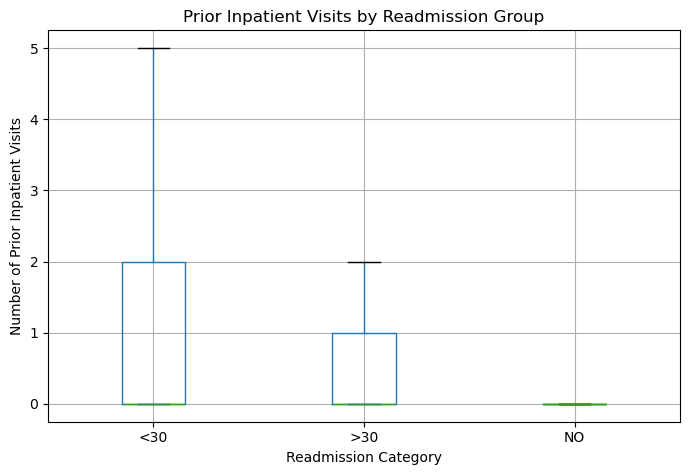

In [39]:
fig, ax = plt.subplots(figsize=(7, 5))

df_clean.boxplot(
    column="number_inpatient",
    by="readmitted",
    ax=ax,
    showfliers=False
)

ax.set_title("Prior Inpatient Visits by Readmission Group")
ax.set_xlabel("Readmission Category")
ax.set_ylabel("Number of Prior Inpatient Visits")

plt.suptitle("")
plt.tight_layout()
fig.savefig("../Figures/Prior Inpatient Visits by Readmission Group.png", dpi=300, bbox_inches="tight")
plt.show()

### Figure interpretation: Prior inpatient visits

The `<30` group shows more previous inpatient use than the other readmission groups. The central distributions overlap, but the shift is still visible. Outlier markers are hidden only for readability; no observations were removed from the analysis.


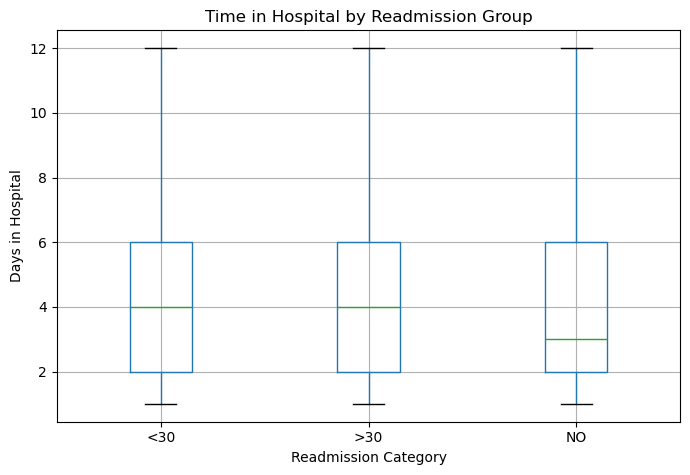

In [40]:
fig, ax = plt.subplots(figsize=(7, 5))

df_clean.boxplot(
    column="time_in_hospital",
    by="readmitted",
    ax=ax,
    showfliers=False
)

ax.set_title("Time in Hospital by Readmission Group")
ax.set_xlabel("Readmission Category")
ax.set_ylabel("Days in Hospital")

plt.suptitle("")
plt.tight_layout()
fig.savefig("../Figures/Time in Hospital by Readmission Group.png", dpi=300, bbox_inches="tight")
plt.show()

### Figure interpretation: Time in hospital

Length of stay is slightly higher for the `<30` group on average, but there is substantial overlap across all three readmission categories. This suggests that `time_in_hospital` alone provides limited separation between outcomes.


## Q3 — Which variables appear most strongly associated with 30-day readmission?


In [41]:
def pooled_smd(data, variable, group_col="early_readmission"):
    group_1 = data.loc[
        data[group_col] == 1, variable
    ].dropna()

    group_0 = data.loc[
        data[group_col] == 0, variable
    ].dropna()

    mean_diff = group_1.mean() - group_0.mean()

    pooled_sd = np.sqrt(
        (
            group_1.var(ddof=1) +
            group_0.var(ddof=1)
        ) / 2
    )

    if pooled_sd == 0:
        return np.nan

    return mean_diff / pooled_sd

In [42]:
smd_results = pd.DataFrame({
    "variable": q2_variables,
    "SMD": [
        pooled_smd(df_clean, col)
        for col in q2_variables
    ]
})

smd_results["absolute_SMD"] = (
    smd_results["SMD"].abs()
)

smd_results = smd_results.sort_values(
    "absolute_SMD",
    ascending=False
)

display(smd_results.round(3))

,variable,SMD,absolute_SMD
3,number_inpatient,0.415,0.415
6,number_diagnoses,0.163,0.163
5,number_emergency,0.157,0.157
0,time_in_hospital,0.140,0.140
1,num_medications,0.122,0.122
2,num_lab_procedures,0.065,0.065
4,number_outpatient,0.059,0.059


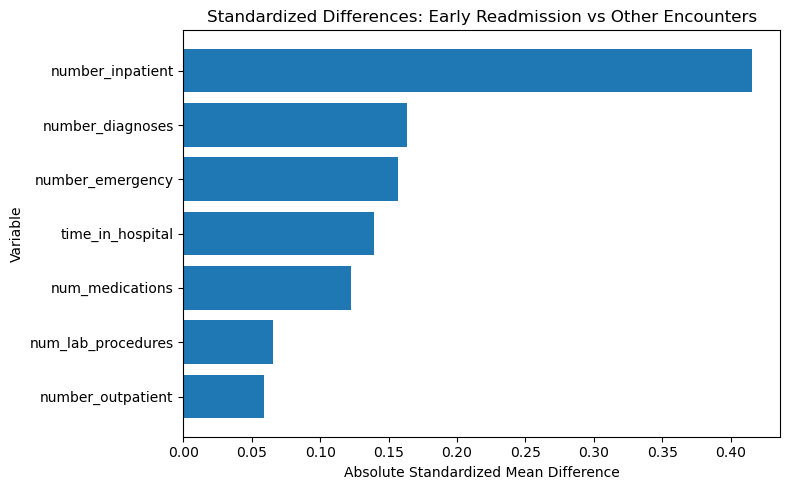

In [43]:
fig, ax = plt.subplots(figsize=(8, 5))

plot_data = smd_results.sort_values(
    "absolute_SMD"
)

ax.barh(
    plot_data["variable"],
    plot_data["absolute_SMD"]
)

ax.set_title(
    "Standardized Differences: Early Readmission vs Other Encounters"
)
ax.set_xlabel("Absolute Standardized Mean Difference")
ax.set_ylabel("Variable")

plt.tight_layout()
fig.savefig("../Figures/Standardized Differences - Early Readmission vs Other Encounters.png", dpi=300, bbox_inches="tight")
plt.show()

### Figure interpretation: Standardized mean differences

Among the selected numeric utilization variables, **`number_inpatient` shows the largest absolute standardized difference** between early-readmission encounters and the remaining observations. The other numeric variables show weaker separation. These are descriptive associations and should not be interpreted as causal effects.


In [44]:
correlation_matrix = (
    df_clean[q2_variables]
    .corr()
)

display(correlation_matrix.round(2))

,time_in_hospital,num_medications,num_lab_procedures,number_inpatient,number_outpatient,number_emergency,number_diagnoses
time_in_hospital,1.00,0.47,0.32,0.07,-0.01,-0.01,0.22
num_medications,0.47,1.00,0.27,0.06,0.05,0.01,0.26
num_lab_procedures,0.32,0.27,1.00,0.04,-0.01,-0.00,0.15
number_inpatient,0.07,0.06,0.04,1.00,0.11,0.27,0.10
number_outpatient,-0.01,0.05,-0.01,0.11,1.00,0.09,0.09
number_emergency,-0.01,0.01,-0.00,0.27,0.09,1.00,0.06
number_diagnoses,0.22,0.26,0.15,0.10,0.09,0.06,1.00


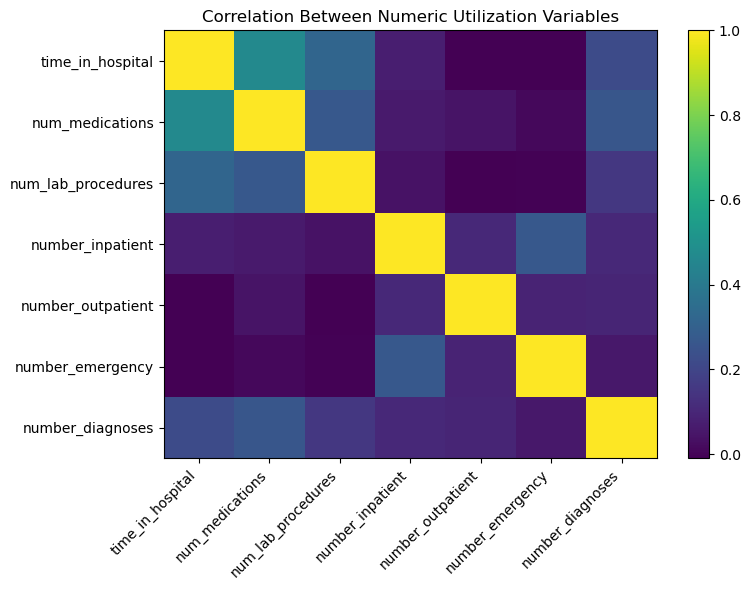

In [45]:
fig, ax = plt.subplots(figsize=(8, 6))

im = ax.imshow(
    correlation_matrix,
    aspect="auto"
)

ax.set_xticks(range(len(q2_variables)))
ax.set_yticks(range(len(q2_variables)))

ax.set_xticklabels(
    q2_variables,
    rotation=45,
    ha="right"
)

ax.set_yticklabels(q2_variables)

fig.colorbar(im, ax=ax)

ax.set_title(
    "Correlation Between Numeric Utilization Variables"
)

plt.tight_layout()
fig.savefig("../Figures/Correlation Between Numeric Utilization Variables.png", dpi=300, bbox_inches="tight")
plt.show()

### Figure interpretation: Correlation matrix

The selected numeric utilization variables show mostly weak to moderate pairwise correlations. The largest observed correlation is about **0.47** between `time_in_hospital` and `num_medications`. No very strong pairwise relationship is evident, although Pearson correlation should be interpreted cautiously for skewed and zero-inflated count variables.


In [66]:
discharge_disposition_map = {
    1: "Home",
    2: "Short term hospital",
    3: "SNF",
    4: "ICF",
    5: "Other inpatient institution",
    6: "Home health service",
    7: "Left AMA",
    8: "Home IV provider",
    9: "Readmitted to same hospital",
    10: "Neonatal transfer",
    11: "Expired",
    12: "Still patient / outpatient return",
    13: "Hospice home",
    14: "Hospice medical facility",
    15: "Swing bed",
    16: "External outpatient services",
    17: "Internal outpatient services",
    18: "Missing",
    19: "Expired at home",
    20: "Expired in medical facility",
    21: "Expired place unknown",
    22: "Rehabilitation facility",
    23: "Long term care hospital",
    24: "Nursing facility",
    25: "Not Mapped",
    26: "Unknown/Invalid",
    27: "Federal health care facility",
    28: "Psychiatric hospital"
}

df_clean["discharge_disposition"] = (
    df_clean["discharge_disposition_id"]
    .map(discharge_disposition_map)
)

In [67]:
admission_source_map = {
    1: "Physician Referral",
    2: "Clinic Referral",
    3: "HMO Referral",
    4: "Transfer from hospital",
    5: "Transfer from SNF",
    6: "Transfer from other facility",
    7: "Emergency Room",
    8: "Court / Law Enforcement",
    9: "Not Available",
    10: "Critical Access Hospital",
    11: "Normal Delivery",
    12: "Premature Delivery",
    13: "Sick Baby",
    14: "Extramural Birth",
    15: "Not Available",
    17: "Missing",
    18: "Home Health Agency",
    19: "Readmission to Home Health Agency",
    20: "Not Mapped",
    21: "Unknown/Invalid",
    22: "Hospital inpatient transfer",
    23: "Born inside hospital",
    24: "Born outside hospital",
    25: "Ambulatory Surgery Center",
    26: "Hospice"
}

df_clean["admission_source"] = (
    df_clean["admission_source_id"]
    .map(admission_source_map)
)

In [68]:
print(df_clean["admission_type"].value_counts(dropna=False))
print(df_clean["admission_source"].value_counts(dropna=False))
print(df_clean["discharge_disposition"].value_counts(dropna=False))

admission_type
Emergency        53990
Elective         18869
Urgent           18480
NULL              5291
Not Available     4785
Not Mapped         320
Trauma Center       21
Newborn             10
Name: count, dtype: int64
admission_source
Emergency Room                  57494
Physician Referral              29565
Missing                          6781
Transfer from hospital           3187
Transfer from other facility     2264
Clinic Referral                  1104
Transfer from SNF                 855
HMO Referral                      187
Not Mapped                        161
Not Available                     125
Court / Law Enforcement            16
Hospital inpatient transfer        12
Critical Access Hospital            8
Extramural Birth                    2
Normal Delivery                     2
Ambulatory Surgery Center           2
Sick Baby                           1
Name: count, dtype: int64
discharge_disposition
Home                                 60234
SNF                  

### Administrative category patterns

Emergency admissions and Emergency Room sources account for a large share of encounters, while discharge to home is the most common disposition. These distributions provide context for later subgroup comparisons, but frequency alone does not indicate an association with early readmission.


In [69]:
def early_readmission_by_group(data, variable):
    result = (
        data.groupby(variable, dropna=False)["early_readmission"]
        .agg(["count", "sum", "mean"])
    )

    result["early_readmission_percent"] = result["mean"] * 100

    return result[
        ["count", "sum", "early_readmission_percent"]
    ].sort_values(
        "early_readmission_percent",
        ascending=False
    )

In [70]:
race_readmission = early_readmission_by_group(
    df_clean,
    "race"
)

gender_readmission = early_readmission_by_group(
    df_clean,
    "gender"
)

display(race_readmission.round(2))
display(gender_readmission.round(2))

,count,sum,early_readmission_percent
race,,,
Caucasian,76099,8592,11.29
AfricanAmerican,19210,2155,11.22
Hispanic,2037,212,10.41
Asian,641,65,10.14
Other,1506,145,9.63
Missing,2273,188,8.27


,count,sum,early_readmission_percent
gender,,,
Female,54708,6152,11.25
Male,47055,5205,11.06
Missing,3,0,0.00


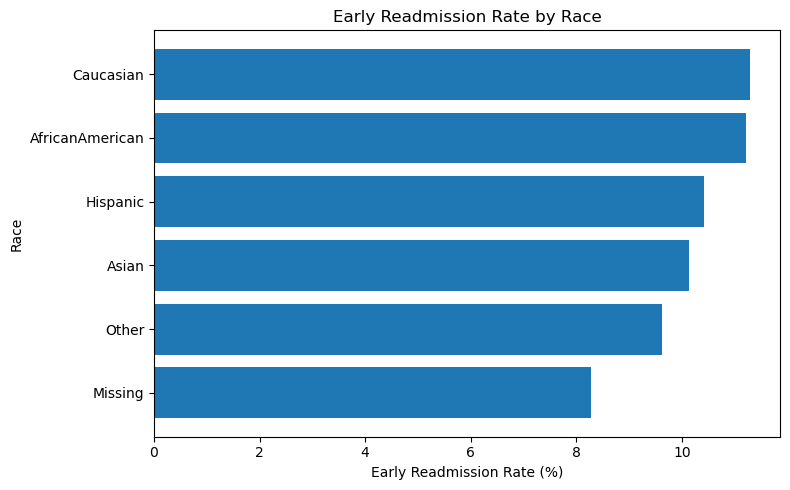

In [71]:
fig, ax = plt.subplots(figsize=(8, 5))

race_plot = race_readmission.sort_values(
    "early_readmission_percent"
)

ax.barh(
    race_plot.index,
    race_plot["early_readmission_percent"]
)

ax.set_title("Early Readmission Rate by Race")
ax.set_xlabel("Early Readmission Rate (%)")
ax.set_ylabel("Race")

plt.tight_layout()
fig.savefig("../Figures/Early Readmission Rate by Race.png", dpi=300, bbox_inches="tight")
plt.show()

### Figure interpretation: Early readmission by race

Early readmission percentages differ only modestly across the largest race groups. Smaller race groups have fewer observations, so their rates are less stable and should be interpreted cautiously. These raw outcome differences do not establish whether a fitted model is fair across race groups.


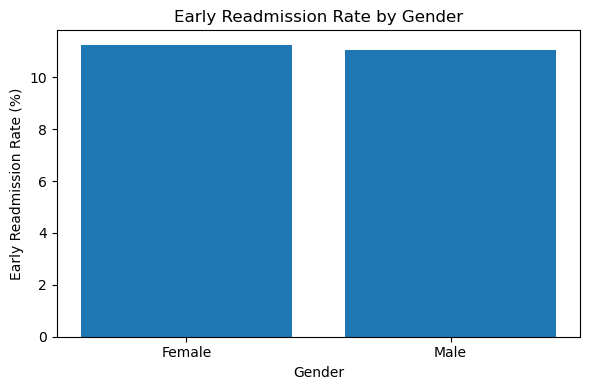

In [72]:
fig, ax = plt.subplots(figsize=(6, 4))

gender_plot = gender_readmission.loc[
    ["Female", "Male"]
]

ax.bar(
    gender_plot.index,
    gender_plot["early_readmission_percent"]
)

ax.set_title("Early Readmission Rate by Gender")
ax.set_xlabel("Gender")
ax.set_ylabel("Early Readmission Rate (%)")

plt.tight_layout()
fig.savefig("../Figures/Early Readmission Rate by Gender.png", dpi=300, bbox_inches="tight")
plt.show()

### Figure interpretation: Early readmission by gender

Female and male encounters have very similar observed early readmission rates, approximately **11.25%** and **11.06%**. This describes the raw outcome distribution only. Model fairness must later be evaluated using subgroup performance measures such as Recall and false-negative rate.


In [73]:
from scipy.stats import chi2_contingency

In [74]:
def cramers_v(data, variable, target="early_readmission"):
    table = pd.crosstab(
        data[variable],
        data[target]
    )

    chi2 = chi2_contingency(table)[0]
    n = table.to_numpy().sum()

    phi2 = chi2 / n
    r, k = table.shape

    denominator = min(k - 1, r - 1)

    if denominator == 0:
        return np.nan

    return np.sqrt(phi2 / denominator)

In [75]:
categorical_association_vars = [
    "race",
    "gender",
    "age",
    "admission_type",
    "admission_source",
    "discharge_disposition",
    "A1Cresult",
    "max_glu_serum",
    "change",
    "diabetesMed",
    "insulin"
]

In [76]:
categorical_associations = pd.DataFrame({
    "variable": categorical_association_vars,
    "cramers_v": [
        cramers_v(df_clean, col)
        for col in categorical_association_vars
    ]
})

categorical_associations = (
    categorical_associations
    .sort_values("cramers_v", ascending=False)
)

display(categorical_associations.round(3))

,variable,cramers_v
5,discharge_disposition,0.125
10,insulin,0.043
2,age,0.034
9,diabetesMed,0.027
4,admission_source,0.023
8,change,0.019
6,A1Cresult,0.019
3,admission_type,0.016
0,race,0.016
7,max_glu_serum,0.012


### Categorical associations

Among the categorical variables examined, **`discharge_disposition` has the largest Cramér's V, about 0.125**, while the remaining associations are weak. This variable requires particular caution because death and hospice categories directly affect whether a patient has an opportunity to be readmitted. The observed association therefore should not be interpreted as a simple clinical risk effect.


### Diagnosis Grouping and Readmission


In [77]:
def group_icd9(code):
    if pd.isna(code) or code == "Missing":
        return "Missing"

    code = str(code).strip()

    if code.startswith(("V", "E")):
        return "Other"

    try:
        numeric_code = float(code)
    except ValueError:
        return "Other"

    if 390 <= numeric_code <= 459 or numeric_code == 785:
        return "Circulatory"

    elif 460 <= numeric_code <= 519 or numeric_code == 786:
        return "Respiratory"

    elif 520 <= numeric_code <= 579 or numeric_code == 787:
        return "Digestive"

    elif 250 <= numeric_code < 251:
        return "Diabetes"

    elif 800 <= numeric_code <= 999:
        return "Injury"

    elif 710 <= numeric_code <= 739:
        return "Musculoskeletal"

    elif 580 <= numeric_code <= 629 or numeric_code == 788:
        return "Genitourinary"

    elif 140 <= numeric_code <= 239:
        return "Neoplasms"

    else:
        return "Other"

In [78]:
for col in ["diag_1", "diag_2", "diag_3"]:
    new_col = f"{col}_group"

    df_clean[new_col] = (
        df_clean[col]
        .apply(group_icd9)
    )

In [79]:
for col in [
    "diag_1_group",
    "diag_2_group",
    "diag_3_group"
]:
    print(f"\n{col}")

    display(
        df_clean[col]
        .value_counts(dropna=False)
        .to_frame("count")
    )


diag_1_group


,count
diag_1_group,
Circulatory,30437
Other,18172
Respiratory,14423
Digestive,9475
Diabetes,8757
Injury,6974
Genitourinary,5117
Musculoskeletal,4957
Neoplasms,3433



diag_2_group


,count
diag_2_group,
Circulatory,31881
Other,26553
Diabetes,12794
Respiratory,10895
Genitourinary,8376
Digestive,4170
Neoplasms,2547
Injury,2428
Musculoskeletal,1764



diag_3_group


,count
diag_3_group,
Circulatory,30306
Other,29195
Diabetes,17157
Respiratory,7358
Genitourinary,6680
Digestive,3930
Injury,1946
Musculoskeletal,1915
Neoplasms,1856


The raw diagnosis columns contain hundreds of ICD-9 codes, so they are grouped into broader clinical categories to make the EDA interpretable and reduce high cardinality. Circulatory diagnoses and the broad `Other` category are common across the grouped diagnosis fields.


In [80]:
diag1_readmission = early_readmission_by_group(
    df_clean,
    "diag_1_group"
)

display(diag1_readmission.round(2))

,count,sum,early_readmission_percent
diag_1_group,,,
Missing,21,5,23.81
Diabetes,8757,1137,12.98
Injury,6974,854,12.25
Other,18172,2086,11.48
Circulatory,30437,3485,11.45
Genitourinary,5117,555,10.85
Digestive,9475,1015,10.71
Neoplasms,3433,346,10.08
Respiratory,14423,1403,9.73


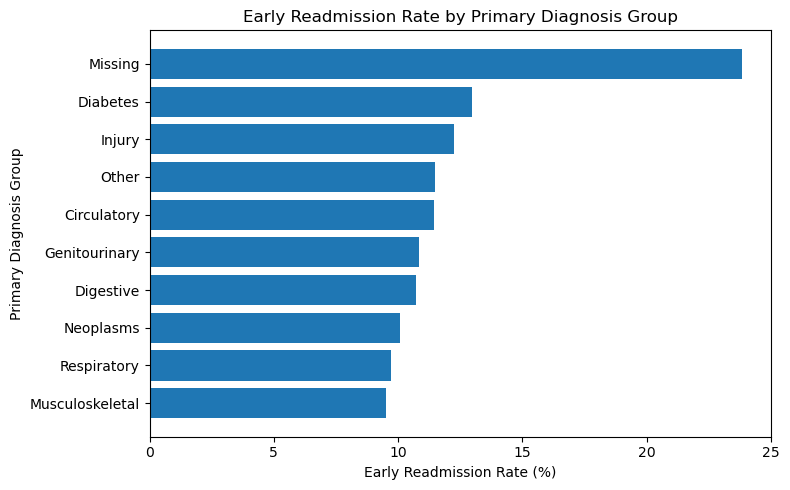

In [81]:
fig, ax = plt.subplots(figsize=(8, 5))

diag_plot = diag1_readmission.sort_values(
    "early_readmission_percent"
)

ax.barh(
    diag_plot.index,
    diag_plot["early_readmission_percent"]
)

ax.set_title(
    "Early Readmission Rate by Primary Diagnosis Group"
)
ax.set_xlabel("Early Readmission Rate (%)")
ax.set_ylabel("Primary Diagnosis Group")

plt.tight_layout()
fig.savefig("../Figures/Early Readmission Rate by Primary Diagnosis Group.png", dpi=300, bbox_inches="tight")
plt.show()

### Figure interpretation: Early readmission by primary diagnosis group

Among the larger primary diagnosis groups, **Diabetes has the highest observed early readmission rate at about 13%**. The `Missing` group shows a higher percentage, but it contains only 21 encounters, so that estimate is unstable and should not be overinterpreted.


In [82]:
diagnosis_associations = pd.DataFrame({
    "variable": [
        "diag_1_group",
        "diag_2_group",
        "diag_3_group"
    ],
    "cramers_v": [
        cramers_v(df_clean, col)
        for col in [
            "diag_1_group",
            "diag_2_group",
            "diag_3_group"
        ]
    ]
})

display(
    diagnosis_associations
    .sort_values("cramers_v", ascending=False)
    .round(3)
)

,variable,cramers_v
2,diag_3_group,0.032
0,diag_1_group,0.031
1,diag_2_group,0.023


The grouped diagnosis variables show only weak overall associations with early readmission. Cramér's V is approximately **0.031** for the primary diagnosis group, **0.023** for the secondary group, and **0.032** for the tertiary group.


In [83]:
mapping_validation = pd.Series({
    "unmapped_admission_type":
        df_clean["admission_type"].isna().sum(),

    "unmapped_admission_source":
        df_clean["admission_source"].isna().sum(),

    "unmapped_discharge_disposition":
        df_clean["discharge_disposition"].isna().sum()
})

display(mapping_validation)


unmapped_admission_type           0
unmapped_admission_source         0
unmapped_discharge_disposition    0
dtype: int64

The mapping validation confirms that the observed admission type, admission source, and discharge disposition IDs were mapped successfully.


## Final Cleaning Decision Log


In [84]:
cleaning_decision_log = pd.DataFrame({
    "issue": [
        "Exact duplicate rows",
        "Repeat patient encounters",
        "Missing weight",
        "Missing medical specialty",
        "Missing payer code",
        "Missing race",
        "Missing diagnosis values",
        "Constant features",
        "Extreme numeric values",
        "Death or hospice discharges",
        "Raw ICD-9 diagnosis codes",
        "Patient identifier",
        "Encounter identifier",
        "Sensitive attributes"
    ],

    "finding": [
        "No exact duplicate rows found",
        "16,773 patients had multiple encounters",
        "96.86% missing",
        "49.08% missing",
        "39.56% missing",
        "2.23% missing",
        "Low missingness in diag_1, diag_2 and diag_3",
        "examide and citoglipton had one unique value",
        "Several utilization variables had IQR flagged observations",
        "2,423 encounters were identified",
        "Hundreds of unique ICD-9 codes",
        "patient_nbr identifies patients",
        "encounter_id uniquely identifies encounters",
        "race, gender and age are needed for subgroup analysis"
    ],

    "decision": [
        "No action needed",
        "Retain; use patient grouping to prevent leakage",
        "Exclude from modeling",
        "Retain with missing category",
        "Retain with missing category",
        "Retain with missing category",
        "Retain with missing category",
        "Exclude from modeling",
        "Retain unless independently shown invalid",
        "Flag for modeling cohort decision",
        "Use grouped diagnosis categories for interpretation/modeling",
        "Exclude as predictor; retain for grouped split",
        "Exclude as predictor",
        "Retain for fairness analysis"
    ]
})

display(cleaning_decision_log)

,issue,finding,decision
0,Exact duplicate rows,No exact duplicate rows found,No action needed
1,Repeat patient encounters,"16,773 patients had multiple encounters",Retain; use patient grouping to prevent leakage
2,Missing weight,96.86% missing,Exclude from modeling
3,Missing medical specialty,49.08% missing,Retain with missing category
4,Missing payer code,39.56% missing,Retain with missing category
5,Missing race,2.23% missing,Retain with missing category
6,Missing diagnosis values,"Low missingness in diag_1, diag_2 and diag_3",Retain with missing category
7,Constant features,examide and citoglipton had one unique value,Exclude from modeling
8,Extreme numeric values,Several utilization variables had IQR flagged ...,Retain unless independently shown invalid
9,Death or hospice discharges,"2,423 encounters were identified",Flag for modeling cohort decision


### Cleaning summary

The cleaning strategy avoids aggressive deletion. Exact duplicates were not present, repeat patient encounters were retained, missingness was documented explicitly, constant features were marked for exclusion, and statistically extreme utilization values were kept unless there was independent evidence that they were invalid.


## Modeling Handoff


In [85]:
modeling_exclude = [
    "encounter_id",
    "patient_nbr",
    "repeat_patient",
    "early_readmission",
    "weight",
    "examide",
    "citoglipton"
]

print("Columns that should not be used directly as predictors:")
for col in modeling_exclude:
    print("-", col)

Columns that should not be used directly as predictors:
- encounter_id
- patient_nbr
- repeat_patient
- early_readmission
- weight
- examide
- citoglipton


`patient_nbr` should be retained long enough to create a patient-aware train/test split, but it should **not** be used as a predictor. `encounter_id`, `repeat_patient`, and the EDA helper variable `early_readmission` should also not be used as predictors. `weight`, `examide`, and `citoglipton` are marked for exclusion for the reasons documented above. Sensitive attributes such as race, gender, and age should remain available for later fairness evaluation.


## EDA Summary

Three findings stand out from the cleaning and EDA stage:

1. Early readmission within 30 days is a minority outcome, representing about **11%** of encounters.
2. **Prior inpatient utilization** shows the clearest numeric separation between early-readmission encounters and the rest.
3. Most categorical associations are weak; `discharge_disposition` shows the largest association among those examined, but its interpretation is complicated by death and hospice categories.

These findings describe patterns in the observed data. They do not establish causation and should be carried forward cautiously into the modeling and fairness stages.


## Part 2 — Modeling

**Modeling objective:** predict early readmission within 30 days using the binary target `early_readmission`.

The original `readmitted` variable has three levels (`<30`, `>30`, `NO`). We use a binary target because the specific modeling question is whether an encounter is followed by an early readmission within 30 days: `1` = `<30`, `0` = not `<30`. This is a task-driven choice, not a choice made because it produces higher Accuracy.


### Q4 — Can a baseline model predict readmission risk?

The four requested classifiers are compared together: **Logistic Regression, Decision Tree, Random Forest, and XGBoost**. because `<30` is a minority class, the decision threshold is tuned on a patient-separated validation set using **F2-score**, which gives more weight to Recall.

In [86]:
# Modeling imports
import matplotlib.pyplot as plt
import seaborn as sns
import math
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import RocCurveDisplay
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    roc_auc_score,
    average_precision_score,
    balanced_accuracy_score
)
from IPython.display import Markdown
from xgboost import XGBClassifier
import warnings

warnings.filterwarnings("ignore")
RANDOM_STATE = 123


In [87]:
modeling_exclude = [
    "encounter_id",
    "patient_nbr",
    "repeat_patient",
    "early_readmission",
    "weight",
    "examide",
    "citoglipton"
]

target = "early_readmission"
group_variable = "patient_nbr"

feature_columns = [
    col for col in df_clean.columns
    if col not in modeling_exclude + ["readmitted"]
]
df_clean = df_clean[df_clean['death_or_hospice'] == False].copy()
X = df_clean[feature_columns].copy()
y = df_clean[target].astype(int).copy()
groups = df_clean[group_variable].copy()

print(f"Number of predictor variables: {len(feature_columns)}")
print("Target distribution:")
display((y.value_counts(normalize=True) * 100).rename_axis(target).to_frame("percent").round(2))


Number of predictor variables: 51
Target distribution:


,percent
early_readmission,
0,88.61
1,11.39


The table above shows that we are facing a class imbalance in the target variable

In [88]:
#To prevent from Data Leakage
gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=RANDOM_STATE
)

train_idx, test_idx = next(
    gss.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()
y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

print("Train shape:", X_train.shape)
print("Test shape :", X_test.shape)
print("Unique patients in train:", groups.iloc[train_idx].nunique())
print("Unique patients in test :", groups.iloc[test_idx].nunique())
print("Patient overlap:", len(
    set(groups.iloc[train_idx]).intersection(set(groups.iloc[test_idx]))
))


Train shape: (79395, 51)
Test shape : (19948, 51)
Unique patients in train: 55992
Unique patients in test : 13998
Patient overlap: 0


In [89]:
# Detect numeric and categorical predictors from the actual dataframe.
numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = [
    col for col in X_train.columns
    if col not in numeric_features
]

print("Numeric predictors:", len(numeric_features))
print("Categorical predictors:", len(categorical_features))

try:
    onehot = OneHotEncoder(
        handle_unknown="ignore",
        min_frequency=2,
        sparse_output=True
    )
except TypeError:
    onehot = OneHotEncoder(
        handle_unknown="ignore",
        min_frequency=2,
        sparse=True
    )
#Normalize for categorical Data
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
#one hot encoding for categorical Data
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", onehot)
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])


Numeric predictors: 11
Categorical predictors: 40


In [90]:
def build_models():
    positive_weight = (y_train == 0).sum() / (y_train == 1).sum()

    return {
        "Logistic Regression": Pipeline([
            ("preprocessor", preprocessor),
            ("classifier", LogisticRegression(
                max_iter=2000,
                class_weight="balanced",
                random_state=RANDOM_STATE
            ))
        ]),
        "Decision Tree": Pipeline([
            ("preprocessor", preprocessor),
            ("classifier", DecisionTreeClassifier(
                max_depth=8,
                min_samples_leaf=50,
                class_weight="balanced",
                random_state=RANDOM_STATE
            ))
        ]),
        "Random Forest": Pipeline([
            ("preprocessor", preprocessor),
            ("classifier", RandomForestClassifier(
                n_estimators=250,
                max_depth=16,
                min_samples_leaf=10,
                class_weight="balanced_subsample",
                random_state=RANDOM_STATE,
                n_jobs=-1
            ))
        ]),
        "XGBoost": Pipeline([
            ("preprocessor", preprocessor),
            ("classifier", XGBClassifier(
                n_estimators=250,
                max_depth=5,
                learning_rate=0.05,
                min_child_weight=5,
                subsample=0.8,
                colsample_bytree=0.8,
                reg_lambda=1.0,
                scale_pos_weight=positive_weight,
                objective="binary:logistic",
                eval_metric="logloss",
                tree_method="hist",
                random_state=RANDOM_STATE,
                n_jobs=-1
            ))
        ])
    }


def select_threshold(y_true, y_prob, beta=2.0):
    best_thresh, best_score = 0.5, -1.0
    #testing threshholds from 0.05 t0 0.5
    for thresh in np.linspace(0.05, 0.50, 46):
        preds = (y_prob >= thresh).astype(int)
        score = fbeta_score(y_true, preds, beta=beta, zero_division=0)
        
        if score > best_score:
            best_score = score
            best_thresh = thresh
            
    return float(best_thresh), float(best_score)


# ۲. تقسیم داده‌ها به Fit و Validation بدون نشت داده
groups_train = groups.iloc[train_idx].copy()
gss_val = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=RANDOM_STATE)
fit_idx, val_idx = next(gss_val.split(X_train, y_train, groups=groups_train))

X_train_fit, y_train_fit = X_train.iloc[fit_idx], y_train.iloc[fit_idx]
X_val, y_val = X_train.iloc[val_idx], y_train.iloc[val_idx]


# Finding the optimal threshold for each model on the Validation data
validation_models = build_models()
thresholds = {}

for name, model in validation_models.items():
    model.fit(X_train_fit, y_train_fit)
    val_probs = model.predict_proba(X_val)[:, 1]
    thresholds[name], _ = select_threshold(y_val, val_probs, beta=2.0)

# Final training on the entire Train and test prediction with dedicated thresholds
fitted_models = build_models()
test_probs = {}
test_preds = {}

for name, model in fitted_models.items():
    model.fit(X_train, y_train)
    test_probs[name] = model.predict_proba(X_test)[:, 1]
    test_preds[name] = (test_probs[name] >= thresholds[name]).astype(int)



logistic_model, logistic_prob, logistic_pred = fitted_models["Logistic Regression"], test_probs["Logistic Regression"], test_preds["Logistic Regression"]
tree_model, tree_prob, tree_pred             = fitted_models["Decision Tree"], test_probs["Decision Tree"], test_preds["Decision Tree"]
rf_model, rf_prob, rf_pred                   = fitted_models["Random Forest"], test_probs["Random Forest"], test_preds["Random Forest"]
xgb_model, xgb_prob, xgb_pred                = fitted_models["XGBoost"], test_probs["XGBoost"], test_preds["XGBoost"]


# showing tables
threshold_table = pd.DataFrame(list(thresholds.items()), columns=["model", "tuned_threshold"])
display(threshold_table.round(3))


,model,tuned_threshold
0,Logistic Regression,0.39
1,Decision Tree,0.38
2,Random Forest,0.45
3,XGBoost,0.41


Table above shows the suitable threshholds for each model

In [91]:
def binary_metrics(y_true, y_pred, y_prob, model_name, threshold=None):
    return {
        "model": model_name,
        "threshold": threshold,
        "accuracy": (y_true == y_pred).mean(),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "recall_<30": recall_score(y_true, y_pred, pos_label=1, zero_division=0),
        "precision_<30": precision_score(y_true, y_pred, pos_label=1, zero_division=0),
        "f1_<30": f1_score(y_true, y_pred, pos_label=1, zero_division=0),
        "roc_auc": roc_auc_score(y_true, y_prob),
        "pr_auc": average_precision_score(y_true, y_prob)
    }


# Baseline at the default 0.50 threshold, kept for comparison.
baseline_model_comparison = pd.DataFrame([
    binary_metrics(y_test, (logistic_prob >= 0.50).astype(int), logistic_prob, "Logistic Regression", 0.50),
    binary_metrics(y_test, (tree_prob >= 0.50).astype(int), tree_prob, "Decision Tree", 0.50),
    binary_metrics(y_test, (rf_prob >= 0.50).astype(int), rf_prob, "Random Forest", 0.50),
    binary_metrics(y_test, (xgb_prob >= 0.50).astype(int), xgb_prob, "XGBoost", 0.50)
])

# Final test-set results use thresholds selected without touching TEST.
model_comparison = pd.DataFrame([
    binary_metrics(y_test, logistic_pred, logistic_prob, "Logistic Regression", thresholds["Logistic Regression"]),
    binary_metrics(y_test, tree_pred, tree_prob, "Decision Tree", thresholds["Decision Tree"]),
    binary_metrics(y_test, rf_pred, rf_prob, "Random Forest", thresholds["Random Forest"]),
    binary_metrics(y_test, xgb_pred, xgb_prob, "XGBoost", thresholds["XGBoost"])
])
display(baseline_model_comparison.round(3))
display(model_comparison.round(3))


,model,threshold,accuracy,balanced_accuracy,recall_<30,precision_<30,f1_<30,roc_auc,pr_auc
0,Logistic Regression,0.5,0.655,0.617,0.568,0.178,0.272,0.664,0.221
1,Decision Tree,0.5,0.590,0.620,0.659,0.167,0.267,0.659,0.212
2,Random Forest,0.5,0.643,0.626,0.603,0.180,0.277,0.674,0.207
3,XGBoost,0.5,0.663,0.634,0.598,0.188,0.287,0.683,0.238


,model,threshold,accuracy,balanced_accuracy,recall_<30,precision_<30,f1_<30,roc_auc,pr_auc
0,Logistic Regression,0.39,0.448,0.597,0.791,0.145,0.245,0.664,0.221
1,Decision Tree,0.38,0.444,0.593,0.786,0.143,0.243,0.659,0.212
2,Random Forest,0.45,0.426,0.602,0.830,0.145,0.247,0.674,0.207
3,XGBoost,0.41,0.474,0.615,0.797,0.152,0.255,0.683,0.238


### Q5 — Is overall accuracy enough?

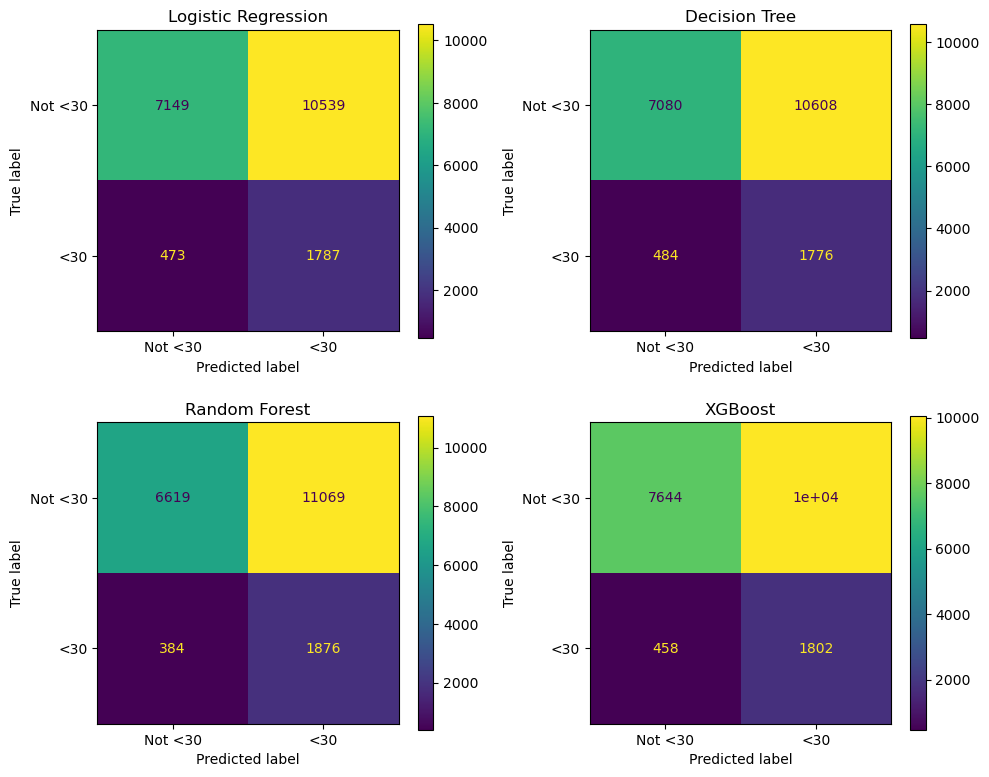

,model,threshold,accuracy,balanced_accuracy,recall_<30,precision_<30,f1_<30
0,Logistic Regression,0.39,0.448,0.597,0.791,0.145,0.245
1,Decision Tree,0.38,0.444,0.593,0.786,0.143,0.243
2,Random Forest,0.45,0.426,0.602,0.830,0.145,0.247
3,XGBoost,0.41,0.474,0.615,0.797,0.152,0.255


In [92]:
# Confusion matrices 
fig, axes = plt.subplots(2, 2, figsize=(10, 8))

model_predictions = {
    "Logistic Regression": logistic_pred,
    "Decision Tree": tree_pred,
    "Random Forest": rf_pred,
    "XGBoost": xgb_pred
}

for ax, (model_name, predictions) in zip(axes.ravel(), model_predictions.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions,
        display_labels=["Not <30", "<30"],
        ax=ax,
        cmap=None
    )
    ax.set_title(model_name)

plt.tight_layout()
fig.savefig("../Figures/Confusion Matrices - All Models.png", dpi=300, bbox_inches="tight")
plt.show()

metric_view = model_comparison[[
    "model", "threshold", "accuracy", "balanced_accuracy",
    "recall_<30", "precision_<30", "f1_<30"
]].copy()
display(metric_view.round(3))


### Q6 — Where does the model fail?

False negatives are especially important because they are true `<30` encounters predicted as not `<30`. The same error analysis is applied to all four tuned models.

In [93]:
def error_summary_for_model(y_true, y_pred, model_name):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {
        "model": model_name,
        "false_positives": fp,
        "false_negatives": fn,
        "true_positives": tp,
        "true_negatives": tn,
        "false_negative_rate": fn / (fn + tp) if (fn + tp) else np.nan
    }

error_summary = pd.DataFrame([
    error_summary_for_model(y_test, logistic_pred, "Logistic Regression"),
    error_summary_for_model(y_test, tree_pred, "Decision Tree"),
    error_summary_for_model(y_test, rf_pred, "Random Forest"),
    error_summary_for_model(y_test, xgb_pred, "XGBoost")
])

display(error_summary.round(3))

best_error = error_summary.loc[error_summary["false_negative_rate"].idxmin()]

,model,false_positives,false_negatives,true_positives,true_negatives,false_negative_rate
0,Logistic Regression,10539,473,1787,7149,0.209
1,Decision Tree,10608,484,1776,7080,0.214
2,Random Forest,11069,384,1876,6619,0.170
3,XGBoost,10044,458,1802,7644,0.203


### Q7 — Which features drive the model?

For Logistic Regression, coefficient magnitude and sign describe the fitted linear association. For Decision Tree, Random Forest, and XGBoost, feature importance describes contribution to the fitted model. These outputs are model explanations, not clinical causal effects.

In [94]:
all_data = []
model_names = ["Logistic Regression", "Decision Tree", "Random Forest", "XGBoost"]

for name in model_names:
    model = fitted_models[name]
    features = model.named_steps["preprocessor"].get_feature_names_out()
    clf = model.named_steps["classifier"]
    
    if name == "Logistic Regression":
        scores = abs(clf.coef_[0])
    else:
        scores = clf.feature_importances_
    df = pd.DataFrame({"model": name, "feature": features, "importance": scores})
    print(f"\n--- {name} ---")
    top_5 = df.sort_values("importance", ascending=False).head(5)
    display(top_5.round(4))
    all_data.append(df)

feature_importance_all = pd.concat(all_data)

top_features = feature_importance_all.groupby("model").head(1).reset_index(drop=True)
display(top_features)


--- Logistic Regression ---


,model,feature,importance
725,Logistic Regression,categorical__diag_2_136,2.4649
1633,Logistic Regression,categorical__diag_3_537,2.2199
1182,Logistic Regression,categorical__diag_2_807,2.1260
512,Logistic Regression,categorical__diag_1_643,2.0669
235,Logistic Regression,categorical__diag_1_271,2.0400



--- Decision Tree ---


,model,feature,importance
9,Decision Tree,numeric__number_inpatient,0.4253
2051,Decision Tree,categorical__discharge_disposition_Home,0.1352
2065,Decision Tree,categorical__discharge_disposition_Rehabilitat...,0.0550
10,Decision Tree,numeric__number_diagnoses,0.0324
1,Decision Tree,numeric__discharge_disposition_id,0.0320



--- Random Forest ---


,model,feature,importance
9,Random Forest,numeric__number_inpatient,0.1318
1,Random Forest,numeric__discharge_disposition_id,0.0543
2051,Random Forest,categorical__discharge_disposition_Home,0.0506
8,Random Forest,numeric__number_emergency,0.0346
2065,Random Forest,categorical__discharge_disposition_Rehabilitat...,0.0320



--- XGBoost ---


,model,feature,importance
2051,XGBoost,categorical__discharge_disposition_Home,0.0196
9,XGBoost,numeric__number_inpatient,0.0186
2065,XGBoost,categorical__discharge_disposition_Rehabilitat...,0.0085
1,XGBoost,numeric__discharge_disposition_id,0.0080
2060,XGBoost,categorical__discharge_disposition_Not Mapped,0.0068


,model,feature,importance
0,Logistic Regression,numeric__admission_type_id,0.165121
1,Decision Tree,numeric__admission_type_id,0.005084
2,Random Forest,numeric__admission_type_id,0.007331
3,XGBoost,numeric__admission_type_id,0.001294


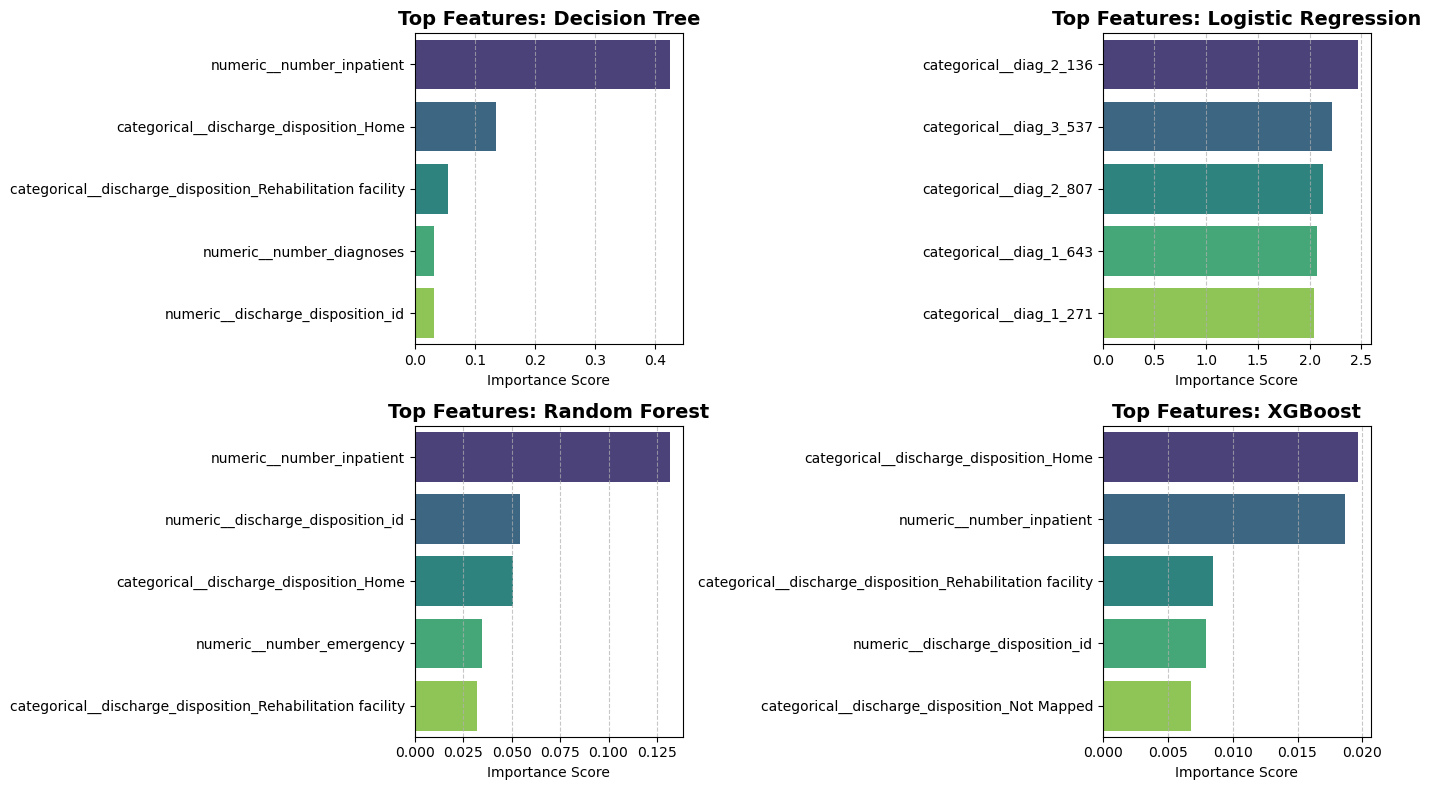

In [95]:
df_plot = feature_importance_all.copy()
df_plot = df_plot.sort_values(["model", "importance"], ascending=[True, False])
top_df = df_plot.groupby("model").head(5).reset_index(drop=True)
models = top_df["model"].unique()
n_models = len(models)
n_cols = 2 
n_rows = math.ceil(n_models / n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(14, 4 * n_rows))
axes = axes.flatten() 
for i, model_name in enumerate(models):
    ax = axes[i]
    model_data = top_df[top_df["model"] == model_name]
    sns.barplot(
        data=model_data,
        x="importance",
        y="feature",
        ax=ax,
        palette="viridis", 
        hue="feature",      
        legend=False
    )    
    ax.set_title(f"Top Features: {model_name}", fontsize=14, fontweight='bold')
    ax.set_xlabel("Importance Score")
    ax.set_ylabel("")
    ax.grid(axis='x', linestyle='--', alpha=0.7)
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
fig.savefig("../Figures/Top Features - All Models.png", dpi=300, bbox_inches="tight")
plt.show()


### Q8 — Is the model fair across patient subgroups?

In [96]:
def subgroup_metrics(data, subgroup, actual_col="actual", pred_col="predicted", model_name=None):
    rows = []
    for group_value, group_data in data.groupby(subgroup, dropna=False, observed=False):
        actual = group_data[actual_col]
        predicted = group_data[pred_col]
        positives = (actual == 1).sum()
        false_negatives = ((actual == 1) & (predicted == 0)).sum()
        rows.append({
            "model": model_name,
            "subgroup": subgroup,
            subgroup: group_value,
            "n": len(group_data),
            "positive_<30": positives,
            "Recall_<30": recall_score(actual, predicted, pos_label=1, zero_division=0),
            "FNR_<30": false_negatives / positives if positives > 0 else np.nan,
            "F1_<30": f1_score(actual, predicted, pos_label=1, zero_division=0)
        })
    return pd.DataFrame(rows)

fairness_test = X_test.copy()
fairness_test["actual"] = y_test.values

all_fairness = []
for model_name, pred in model_predictions.items():
    fairness_test["predicted"] = pred
    for subgroup in ["race", "gender", "age"]:
        all_fairness.append(
            subgroup_metrics(
                fairness_test,
                subgroup,
                model_name=model_name
            )
        )
#Merging tables
all_fairness = pd.concat(all_fairness, ignore_index=True)

fairness_summary = (
    all_fairness
    .groupby(["model", "subgroup"], as_index=False)
    .agg(
        min_Recall=("Recall_<30", "min"),
        max_Recall=("Recall_<30", "max"),
        Recall_gap=("Recall_<30", lambda s: s.max() - s.min()),
        min_FNR=("FNR_<30", "min"),
        max_FNR=("FNR_<30", "max"),
        FNR_gap=("FNR_<30", lambda s: s.max() - s.min())
    )
)

display(fairness_summary.round(3))

largest_gap = fairness_summary.loc[fairness_summary["Recall_gap"].idxmax()]

,model,subgroup,min_Recall,max_Recall,Recall_gap,min_FNR,max_FNR,FNR_gap
0,Decision Tree,age,0.000,0.933,0.933,0.067,1.000,0.933
1,Decision Tree,gender,0.000,0.800,0.800,0.200,0.231,0.031
2,Decision Tree,race,0.714,0.798,0.083,0.202,0.286,0.083
3,Logistic Regression,age,0.000,0.910,0.910,0.090,1.000,0.910
4,Logistic Regression,gender,0.000,0.794,0.794,0.206,0.213,0.006
5,Logistic Regression,race,0.641,0.929,0.288,0.071,0.359,0.288
6,Random Forest,age,0.000,0.967,0.967,0.033,1.000,0.967
7,Random Forest,gender,0.000,0.841,0.841,0.159,0.183,0.024
8,Random Forest,race,0.718,0.836,0.118,0.164,0.282,0.118
9,XGBoost,age,0.000,0.885,0.885,0.115,1.000,0.885


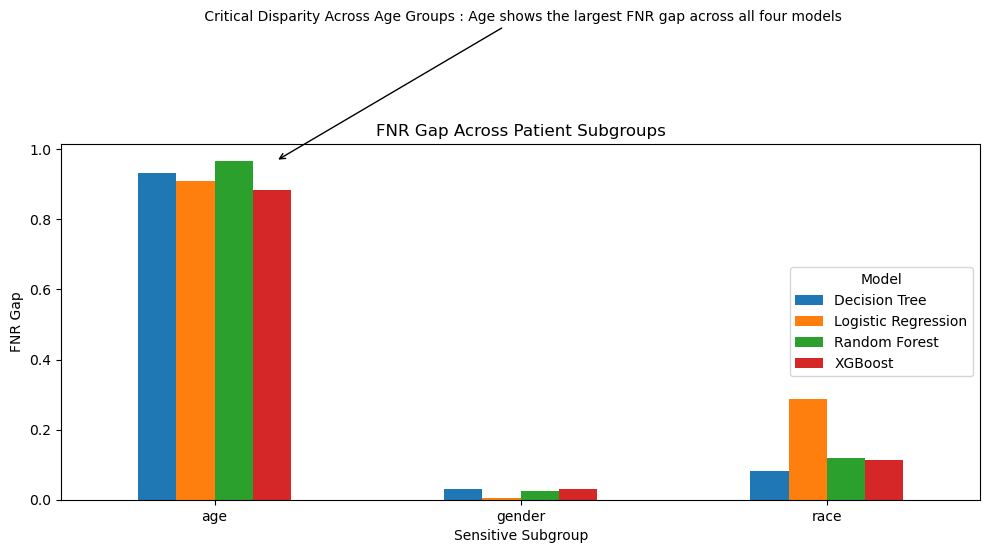

In [97]:
plot_data = fairness_summary.pivot(
    index="subgroup",
    columns="model",
    values="FNR_gap"
)

ax = plot_data.plot(
    kind="bar",
    figsize=(10, 6)
)

ax.set_xlabel("Sensitive Subgroup")
ax.set_ylabel("FNR Gap")
ax.set_title("FNR Gap Across Patient Subgroups")
plt.xticks(rotation=0)
plt.legend(title="Model")

ax.annotate(
    " Critical Disparity Across Age Groups : Age shows the largest FNR gap across all four models",
    
    xy=(0.2, plot_data.loc["age"].max()),
    xytext=(1, plot_data.values.max() +0.4),
    arrowprops=dict(arrowstyle="->"),
    fontsize=10,
    ha="center"
)
plt.tight_layout()
plt.savefig("../Figures/FNR Gap Across Patient Subgroups.png", dpi=300, bbox_inches="tight")
plt.show()

### Fairness Interpretation — FNR Gap

The FNR gap measures the difference between the highest and lowest False Negative Rate across groups within each sensitive attribute.

A larger FNR gap indicates greater variation in the rate at which actual early-readmission cases are missed across subgroups. In the results, the largest gaps are generally observed across age groups, while the gender-based gaps are smaller.

These differences indicate that overall model performance does not fully describe subgroup behavior. Therefore, fairness should be assessed alongside the overall Recall and F1-score.

In [98]:
from sklearn.model_selection import StratifiedGroupKFold, RandomizedSearchCV
from sklearn.metrics import make_scorer, fbeta_score
from xgboost import XGBClassifier

cv = StratifiedGroupKFold(
    n_splits=3,
    shuffle=True,
    random_state=RANDOM_STATE
)

positive_weight = (y_train == 0).sum() / (y_train == 1).sum()

xgb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        scale_pos_weight=positive_weight,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

param_distributions = {
    "classifier__n_estimators": [150, 200, 250],
    "classifier__max_depth": [3, 4, 5],
    "classifier__learning_rate": [0.03, 0.05, 0.08],
    "classifier__min_child_weight": [3, 5, 8],
    "classifier__subsample": [0.8, 1.0],
    "classifier__colsample_bytree": [0.8, 1.0],
    "classifier__reg_lambda": [1.0, 3.0, 5.0]
}

f2_scorer = make_scorer(
    fbeta_score,
    beta=2,
    zero_division=0
)

random_search = RandomizedSearchCV(
    estimator=xgb_pipeline,
    param_distributions=param_distributions,
    n_iter=12,
    scoring=f2_scorer,
    cv=cv,
    random_state=RANDOM_STATE,
    n_jobs=1,
    verbose=1,
    refit=True
)

random_search.fit(
    X_train,
    y_train,
    groups=groups.iloc[train_idx]
)

print("Best parameters:")
print(random_search.best_params_)

print("\nBest CV F2:")
print(round(random_search.best_score_, 3))

Fitting 3 folds for each of 12 candidates, totalling 36 fits
Best parameters:
{'classifier__subsample': 0.8, 'classifier__reg_lambda': 1.0, 'classifier__n_estimators': 200, 'classifier__min_child_weight': 5, 'classifier__max_depth': 3, 'classifier__learning_rate': 0.05, 'classifier__colsample_bytree': 1.0}

Best CV F2:
0.406


In [99]:
xgb_model = random_search.best_estimator_
xgb_prob = xgb_model.predict_proba(X_test)[:, 1]
xgb_pred = (xgb_prob >= 0.50).astype(int)
print("Test Recall:",
      round(recall_score(y_test, xgb_pred), 3))
print("Test F1:",
      round(f1_score(y_test, xgb_pred), 3))

Test Recall: 0.619
Test F1: 0.28


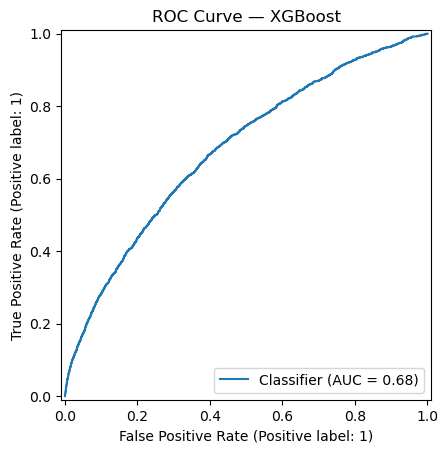

In [100]:
RocCurveDisplay.from_predictions(y_test, xgb_prob)
plt.title("ROC Curve — XGBoost")
plt.savefig("../Figures/ROC Curve - XGBoost.png", dpi=300, bbox_inches="tight")
plt.show()

In [101]:
print(
    classification_report(
        y_test,
        xgb_pred,
        target_names=["Not <30", "<30"],
        digits=3
    )
)

              precision    recall  f1-score   support

     Not <30      0.930     0.643     0.760     17688
         <30      0.181     0.619     0.280      2260

    accuracy                          0.640     19948
   macro avg      0.555     0.631     0.520     19948
weighted avg      0.845     0.640     0.706     19948



Selected Model — XGBoost

Based on the comparison of Logistic Regression, Decision Tree, Random Forest, and XGBoost, XGBoost was selected as the final model because it achieved the highest Recall for the <30 class (0.800)(with thresh =0.5), as well as the highest ROC-AUC (0.684) and PR-AUC (0.238).

To improve the model, RandomizedSearchCV with patient-level cross-validation was used to efficiently explore a limited number of hyperparameter combinations. The selected parameters are therefore the best among the sampled combinations, rather than a guaranteed global optimum.

A global optimum could be searched more systematically using GridSearchCV, which evaluates all specified parameter combinations. However, this approach requires substantially more computational time, especially with multiple cross-validation folds. Since the objective was to obtain a strong and computationally efficient model rather than exhaustively evaluate every possible combination, RandomizedSearchCV was considered sufficient for this analysis.

For the final XGBoost model, the classification threshold was kept at the default value of 0.50. Therefore, predictions with a probability ≥ 0.50 were classified as <30, while probabilities below 0.50 were classified as not <30.

The final XGBoost model was evaluated on the held-out test set using Recall, F1-score, ROC-AUC, PR-AUC, the ROC curve, and the classification report.

### Q9 — What should a hospital administrator or clinician take from this analysis?

Model performance is usable but not deployment-ready as-is. The champion model (XGBoost, threshold = 0.41) identifies about 80% of patients who will be readmitted within 30 days (Recall = 0.797), but Precision is low (~15%). In practice, this means the model will flag several false alarms for every true at-risk patient it catches. Any care-management program built on this model needs enough staff capacity to review a high volume of alerts — otherwise the recall gain is not operationally usable.

The model points to concrete, actionable risk factors. Across the tree-based models, number_inpatient (prior hospitalization history) and discharge_disposition (discharge destination) are consistently the strongest drivers of 30-day readmission. This suggests that post-discharge follow-up resources — care-coordination calls, home health referrals, closer monitoring — should be prioritized for patients with a history of frequent inpatient visits or discharge to skilled nursing/other care facilities. Logistic Regression instead leans on specific diagnosis codes, which is a useful cross-check but should not override the tree-based consensus.

The models exhibit critical performance disparities regarding age, indicating severe algorithmic bias. Across all four models, at least one age cohort has min_Recall = 0.000 and max_FNR = 1.000, meaning the model fails to catch any true readmissions in that group. Disparities observed in gender appear to stem from data scarcity (very few positive cases in some gender subgroups) rather than uniform model bias, while racial performance is comparatively balanced (min_Recall stays above 64% across race groups, with tree-based models showing the smallest gaps). This pattern is consistent with the class imbalance in the target variable interacting with small subgroup sample sizes — subgroups with few positive cases produce unstable, sometimes zero, recall estimates almost by construction, not necessarily because the model treats them differently in a causal sense.

Because of these fairness gaps, the model should not be deployed as an automated decision-maker. It should instead be used as a clinical decision-support tool — a triage signal reviewed by a clinician or case manager, never a substitute for clinical judgment — since feature importances describe statistical association, not causal mechanism, and Precision is too low for fully automated action.

The dataset itself limits how much the current results can be generalized. The data span 1999–2008; clinical protocols, discharge practices, and documentation standards have changed since then, so the model should be revalidated on more recent data before any real-world use.

Recommended next steps before deployment:

Collect additional data for underrepresented age and gender subgroups so recall/FNR estimates in those groups become statistically meaningful.
Apply subgroup-aware threshold calibration or bias-mitigation techniques, rather than a single global threshold.
Externally validate the model on a more recent, independent dataset.
Run a monitored pilot (human-in-the-loop) before full deployment, with ongoing subgroup-level performance tracking rather than a one-time fairness check.

## Additional Figures (added in the revision)

The three figures below support the threshold and fairness findings. All model numbers are executed notebook outputs. Test-set age counts come from re-running the notebook's `GroupShuffleSplit` (`random_state=123`); totals match 19,948 encounters / 2,260 positives. Figures are saved to `../Figures/`.

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Colors used by the three added figures
R, G, B = "#b5122e", "#9aa0a9", "#2f6f9f"

### Figure: Distribution of the binary target (early readmission vs not)

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(13, 4.8))
stages = [("Full dataset\n(n = 101,766)", 11357, 90409),
          ("Modeling cohort\n(n = 99,343)", 11314, 88029),
          ("Test set\n(n = 19,948)", 2260, 17688)]
for a, (t, p, n) in zip(ax, stages):
    tot = p + n
    bars = a.bar(["Not early\nreadmitted (0)", "Early readmission\n<30 days (1)"], [n, p], color=[G, R])
    for b, v in zip(bars, [n, p]):
        a.text(b.get_x() + b.get_width() / 2, v, f"{v:,}\n({100 * v / tot:.2f}%)",
               ha="center", va="bottom", fontsize=9)
    a.set_title(t, fontsize=11)
    a.set_ylim(0, tot * 1.25)
    a.set_yticks([])
    for s in ("top", "right", "left"):
        a.spines[s].set_visible(False)
fig.suptitle("Binary Target: Early Readmission (<30 days) vs Not  (original classes NO and >30 merged into class 0)",
             fontsize=12, fontweight="bold")
plt.tight_layout()
fig.savefig("../Figures/Distribution of Binary Target - Early Readmission.png", dpi=300, bbox_inches="tight")
plt.show()

### Figure: XGBoost (stage A) with vs without the 0.41 threshold

In [ ]:
m = ["Recall (<30)", "Precision (<30)", "F1 (<30)", "Balanced Acc.", "Accuracy", "ROC-AUC", "PR-AUC"]
a50 = [.598, .188, .287, .634, .663, .683, .238]
a41 = [.797, .152, .255, .615, .474, .683, .238]
x = np.arange(len(m))
w = .38
fig, ax = plt.subplots(figsize=(11, 5.4))
b1 = ax.bar(x - w / 2, a50, w, label="Without threshold tuning (default 0.50)", color=G)
b2 = ax.bar(x + w / 2, a41, w, label="Threshold considered (0.41, F2-tuned on validation set)", color=R)
for bs in (b1, b2):
    for b in bs:
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + .01, f"{b.get_height():.3f}",
                ha="center", fontsize=8.5)
ax.set_xticks(x)
ax.set_xticklabels(m)
ax.set_ylim(0, 1.05)
ax.legend(loc="upper right", frameon=False)
ax.set_title("XGBoost (Stage A, held-out test set): Threshold 0.41 vs Default 0.50", fontweight="bold")
ax.text(0, -0.14, "ROC-AUC and PR-AUC do not depend on the threshold. Threshold 0.41 raises Recall from 0.598 to 0.797 "
        "at the cost of Precision and Accuracy.", transform=ax.transAxes, fontsize=9)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
plt.tight_layout()
fig.savefig("../Figures/XGBoost - With vs Without Threshold.png", dpi=300, bbox_inches="tight")
plt.show()

### Figure: Age-subgroup FNR disparity and its statistical support

In [ ]:
ages = ["[0-10)", "[10-20)", "[20-30)", "[30-40)", "[40-50)", "[50-60)", "[60-70)", "[70-80)", "[80-90)", "[90-100)"]
pos = [1, 6, 78, 83, 172, 298, 513, 611, 438, 60]
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
cols = [R if p < 10 else B for p in pos]
bs = ax[0].bar(ages, pos, color=cols)
for b, p in zip(bs, pos):
    ax[0].text(b.get_x() + b.get_width() / 2, p + 8, str(p), ha="center", fontsize=9)
ax[0].set_title("True early readmissions per age band (test set)", fontsize=11)
ax[0].tick_params(axis="x", rotation=45)
ax[0].text(.03, .84, "Red = fewer than 10 positives.\nIn all four models at least one age band\nhas FNR = 1.00 (every case missed).",
           transform=ax[0].transAxes, fontsize=9, color=R)
vals = [0.112, 0.029, 0.885]
ax[1].bar(["Race", "Gender", "Age"], vals, color=[B, B, R])
for i, v in enumerate(vals):
    ax[1].text(i, v + .02, f"{v:.3f}", ha="center")
ax[1].set_ylim(0, 1.05)
ax[1].set_title("FNR gap (max - min), XGBoost Stage A @ 0.41", fontsize=11)
fig.suptitle("Age Subgroup: Severe FNR Disparity and Its Statistical Support", fontsize=12, fontweight="bold")
for a in ax:
    for s in ("top", "right"):
        a.spines[s].set_visible(False)
plt.tight_layout()
fig.savefig("../Figures/Age Subgroup Disparity and Support.png", dpi=300, bbox_inches="tight")
plt.show()